## Menggunakan Kolmogorov Spirnov untuk Drift Detection dengan P-Value 0,05

Script ini tidak memakai library khusus drift. Deteksinya ditulis sendiri dengan scipy.stats:

scipy.stats.ks_2samp: uji Kolmogorov-Smirnov dua sampel, membandingkan distribusi referensi dengan batch (menghasilkan ks_stat dan ks_p).

scipy.stats.norm.cdf: dipakai untuk menghitung p-value dari z-test rata-rata batch (z_p).
numpy dan pandas: untuk data dan perhitungan fitur.

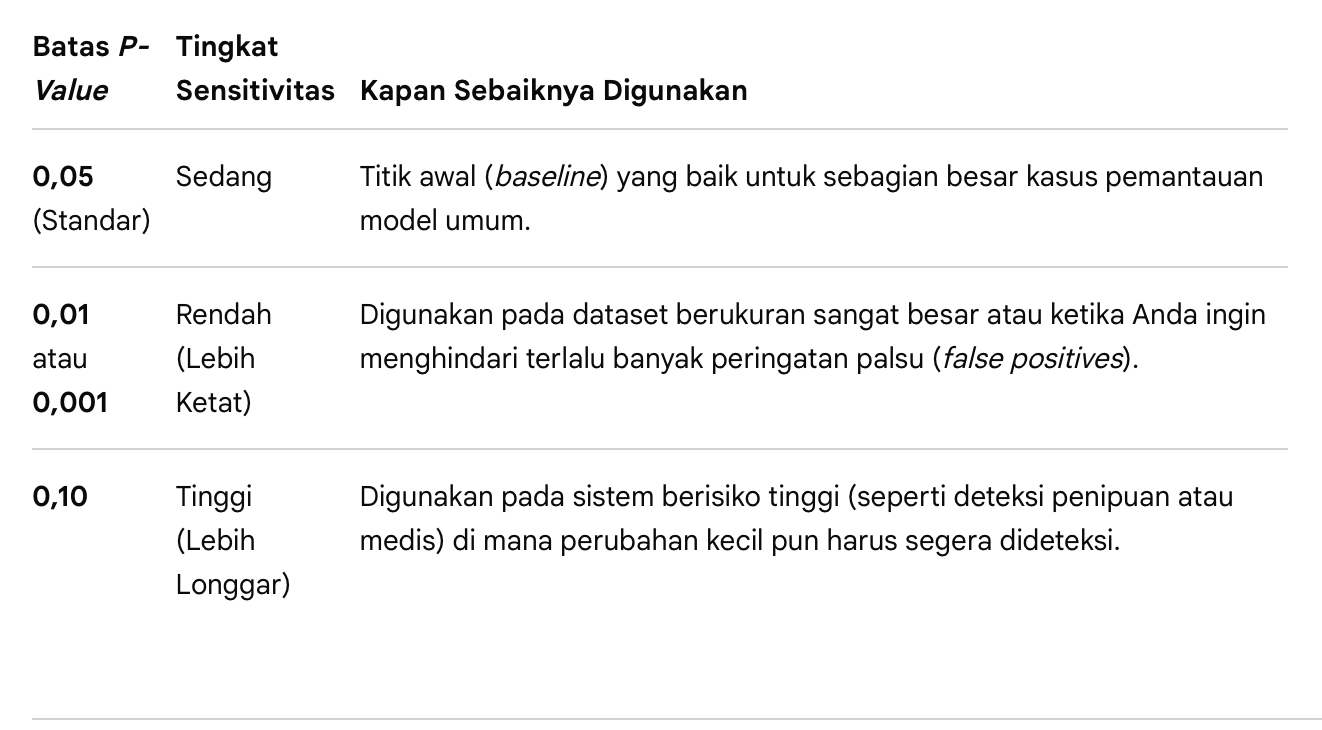

## METODE DRIFT DETECTION
Ada beberapa metode yang umum digunakan.
PSI (Population Stability Index)	Mengukur perubahan distribusi data

KS Test:	Membandingkan distribusi dua sampel numerik

Chi-Square Test:	Membandingkan distribusi data kategorikal

Jensen-Shannon Divergence:	Mengukur perbedaan distribusi probabilitas

Wasserstein Distance:	Mengukur jarak antara dua distribusi

# Demo Data Drift: 5 Data Statis (AI4I 2020 Machine Failure)

**Analogi:** model kamu itu teknisi yang dilatih membaca mesin "normal". Kalau tiba-tiba 5 mesin yang datang semuanya panas, berat, dan aus, teknisinya sedang membaca situasi yang belum pernah ia pelajari. Notebook ini adalah alarm-nya.

Alur: siapkan 2 batch (masing-masing 5 data statis), bandingkan dengan data referensi memakai uji statistik (`scipy`), lalu hit model dari `model/model.ubj` untuk melihat dampaknya ke prediksi.

## 1. Import & konfigurasi

In [105]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from xgboost import XGBClassifier

# ----------------------------- Konfigurasi (static) -----------------------------
MODEL_PATH = Path("model/model.ubj")   # relatif terhadap folder tempat notebook dijalankan
THRESHOLD = 0.5            # ganti dengan threshold hasil tuning dari notebook training
ALPHA = 0.05              # batas p-value per fitur
MIN_DRIFT_FEATURES = 3     # batch dinyatakan drift jika >= sekian fitur menyimpang

TYPE_MAP = {"L": 0, "M": 1, "H": 2}
FEATURES = ["type_enc", "air_temp_k", "process_temp_k", "rpm", "torque_nm",
            "tool_wear_min", "temp_diff_k", "power_w", "wear_torque"]
DRIFT_FEATURES = [f for f in FEATURES if f != "type_enc"]  # numerik saja

## 2. Lima data statis per batch

- **Batch A:** mirip data latih, seharusnya **tidak** drift.
- **Batch B:** mesin panas + beban berat + pahat aus, seharusnya **drift**.

In [106]:
BATCH_NORMAL = [
    {"type": "L", "air_temp_k": 300.1, "process_temp_k": 310.2, "rpm": 1520, "torque_nm": 41.0, "tool_wear_min": 95},
    {"type": "M", "air_temp_k": 299.7, "process_temp_k": 309.6, "rpm": 1610, "torque_nm": 37.5, "tool_wear_min": 140},
    {"type": "L", "air_temp_k": 300.6, "process_temp_k": 310.7, "rpm": 1480, "torque_nm": 44.2, "tool_wear_min": 60},
    {"type": "H", "air_temp_k": 299.9, "process_temp_k": 309.8, "rpm": 1555, "torque_nm": 39.0, "tool_wear_min": 120},
    {"type": "L", "air_temp_k": 300.3, "process_temp_k": 310.4, "rpm": 1500, "torque_nm": 36.8, "tool_wear_min": 180},
]

BATCH_DRIFTED = [
    {"type": "L", "air_temp_k": 304.5, "process_temp_k": 316.0, "rpm": 1290, "torque_nm": 62.0, "tool_wear_min": 225},
    {"type": "L", "air_temp_k": 305.2, "process_temp_k": 316.8, "rpm": 1330, "torque_nm": 58.5, "tool_wear_min": 238},
    {"type": "M", "air_temp_k": 303.9, "process_temp_k": 315.4, "rpm": 1275, "torque_nm": 66.1, "tool_wear_min": 215},
    {"type": "H", "air_temp_k": 304.8, "process_temp_k": 316.3, "rpm": 1350, "torque_nm": 60.4, "tool_wear_min": 230},
    {"type": "L", "air_temp_k": 305.6, "process_temp_k": 317.1, "rpm": 1310, "torque_nm": 64.0, "tool_wear_min": 242},
]

## 3. Feature engineering

Sama persis dengan `make_features` di notebook training (dan `serving/app.py`). Kalau rumus di training berubah, ubah di sini juga.

In [107]:
def make_features(d: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=d.index)
    out["type_enc"] = d["type"].map(TYPE_MAP)
    out["air_temp_k"] = d["air_temp_k"]
    out["process_temp_k"] = d["process_temp_k"]
    out["rpm"] = d["rpm"]
    out["torque_nm"] = d["torque_nm"]
    out["tool_wear_min"] = d["tool_wear_min"]
    out["temp_diff_k"] = d["process_temp_k"] - d["air_temp_k"]
    out["power_w"] = d["torque_nm"] * d["rpm"] * 2 * np.pi / 60
    out["wear_torque"] = d["tool_wear_min"] * d["torque_nm"]
    return out

## 4. Data referensi (simulasi AI4I)

Aproksimasi distribusi data latih AI4I 2020 tanpa CSV asli. Drift selalu dihitung **relatif terhadap acuan ini**.

In [108]:
def load_reference(n: int = 10_000) -> pd.DataFrame:
    rng = np.random.default_rng(42)
    air = rng.normal(300.0, 2.0, n)
    d = pd.DataFrame({
        "type": rng.choice(["L", "M", "H"], n, p=[0.6, 0.3, 0.1]),
        "air_temp_k": air,
        "process_temp_k": air + 10 + rng.normal(0, 1.0, n),
        "rpm": np.clip(rng.normal(1538.8, 179.3, n), 1168, None),
        "torque_nm": np.clip(rng.normal(40.0, 10.0, n), 3.8, None),
        "tool_wear_min": np.clip(rng.normal(108, 64, n), 0, 253),
    })
    return make_features(d)

ref = load_reference()
ref.describe().round(2)

,type_enc,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,wear_torque
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,0.51,299.98,310.00,1538.93,39.78,108.64,10.02,6409.51,4318.77
std,0.67,2.01,2.24,177.53,9.94,60.61,1.00,1770.22,2703.93
min,0.00,291.22,300.97,1168.00,3.80,0.00,6.47,602.02,0.00
25%,0.00,298.65,308.49,1417.38,33.11,65.07,9.34,5189.83,2369.12
50%,0.00,299.97,309.99,1537.00,39.68,107.66,10.02,6329.96,4027.70
75%,1.00,301.30,311.53,1658.74,46.47,150.23,10.69,7540.93,5997.32
max,2.00,308.05,317.75,2314.62,90.07,253.00,13.68,14079.82,15262.98


## 5. Deteksi drift

Per fitur dipakai dua uji: **KS two-sample** (`ks_2samp`) dan **z-test rata-rata batch**. Fitur dianggap menyimpang kalau salah satu p-value < `ALPHA`. Batch dinyatakan drift kalau jumlah fitur menyimpang >= `MIN_DRIFT_FEATURES`.

In [109]:
def detect_drift(ref: pd.DataFrame, batch: pd.DataFrame) -> pd.DataFrame:
    rows, n = [], len(batch)
    for f in DRIFT_FEATURES:
        r, b = ref[f].to_numpy(), batch[f].to_numpy()
        ks_stat, ks_p = stats.ks_2samp(r, b)
        z = (b.mean() - r.mean()) / (r.std(ddof=1) / np.sqrt(n))
        z_p = 2 * (1 - stats.norm.cdf(abs(z)))
        rows.append({"feature": f, "ref_mean": r.mean(), "batch_mean": b.mean(),
                     "ks_stat": ks_stat, "ks_p": ks_p, "z": z, "z_p": z_p,
                     "drift": bool(ks_p < ALPHA or z_p < ALPHA)})
    return pd.DataFrame(rows)


def report_drift(name: str, ref: pd.DataFrame, raw_rows: list) -> pd.DataFrame:
    batch = make_features(pd.DataFrame(raw_rows))
    res = detect_drift(ref, batch)
    n_drift = int(res["drift"].sum())
    share = n_drift / len(res)
    verdict = "DRIFT TERDETEKSI" if n_drift >= MIN_DRIFT_FEATURES else "tidak ada drift"
    print(f"{name}  ->  {verdict}  ({n_drift}/{len(res)} fitur menyimpang = {share:.0%})")
    display(res.assign(drift=res["drift"].map({True: "YA", False: "-"}))
               .style.format({c: "{:,.4g}" for c in ["ref_mean", "batch_mean", "ks_stat", "ks_p", "z", "z_p"]})
               .hide(axis="index"))
    return batch

## 6. Muat model

In [110]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model tidak ditemukan: {MODEL_PATH.resolve()}")

model = XGBClassifier()
model.load_model(str(MODEL_PATH))


def predict(name: str, batch_feats: pd.DataFrame):
    probas = model.predict_proba(batch_feats[FEATURES].astype("float64"))[:, 1]
    print(f"[model] {name}  (threshold {THRESHOLD})")
    for i, p in enumerate(probas, 1):
        print(f"  data {i}: P(failure)={p:.3f} -> {'FAILURE' if p >= THRESHOLD else 'NORMAL'}")
    print(f"  rata-rata P(failure) = {probas.mean():.3f}")

## 7. Batch A: data normal

In [111]:
feats_a = report_drift("BATCH A (5 data normal)", ref, BATCH_NORMAL)
predict("BATCH A (5 data normal)", feats_a)

BATCH A (5 data normal)  ->  tidak ada drift  (0/8 fitur menyimpang = 0%)


feature,ref_mean,batch_mean,ks_stat,ks_p,z,z_p,drift
air_temp_k,300,300.1,0.4443,0.2057,0.1561,0.876,-
process_temp_k,310,310.1,0.4333,0.229,0.1386,0.8898,-
rpm,"1,539","1,533",0.3741,0.3859,-0.07468,0.9405,-
torque_nm,39.78,39.7,0.3819,0.3611,-0.01795,0.9857,-
tool_wear_min,108.6,119,0.2258,0.9113,0.3823,0.7022,-
temp_diff_k,10.02,10.02,0.4684,0.1603,-0.003396,0.9973,-
power_w,"6,410","6,366",0.3843,0.3537,-0.05492,0.9562,-
wear_torque,"4,319","4,620",0.2895,0.7054,0.2493,0.8032,-


[model] BATCH A (5 data normal)  (threshold 0.5)
  data 1: P(failure)=0.187 -> NORMAL
  data 2: P(failure)=0.187 -> NORMAL
  data 3: P(failure)=0.187 -> NORMAL
  data 4: P(failure)=0.187 -> NORMAL
  data 5: P(failure)=0.192 -> NORMAL
  rata-rata P(failure) = 0.188


## 8. Batch B: data bergeser

In [112]:
feats_b = report_drift("BATCH B (5 data bergeser)", ref, BATCH_DRIFTED)
predict("BATCH B (5 data bergeser)", feats_b)

BATCH B (5 data bergeser)  ->  DRIFT TERDETEKSI  (8/8 fitur menyimpang = 100%)


feature,ref_mean,batch_mean,ks_stat,ks_p,z,z_p,drift
air_temp_k,300,304.8,0.9738,2.61e-08,5.356,8.53e-08,YA
process_temp_k,310,316.3,0.9909,1.465e-10,6.301,2.96e-10,YA
rpm,"1,539","1,311",0.849,0.0001583,-2.871,0.004093,YA
torque_nm,39.78,62.2,0.9688,6.193e-08,5.045,4.541e-07,YA
tool_wear_min,108.6,230,0.951,5.816e-07,4.477,7.559e-06,YA
temp_diff_k,10.02,11.52,0.93,3.429e-06,3.342,0.000831,YA
power_w,"6,410","8,533",0.8397,0.0002134,2.683,0.007299,YA
wear_torque,"4,319",1.429e+04,0.9989,1.047e-14,8.248,2.22e-16,YA


[model] BATCH B (5 data bergeser)  (threshold 0.5)
  data 1: P(failure)=0.788 -> FAILURE
  data 2: P(failure)=0.779 -> FAILURE
  data 3: P(failure)=0.777 -> FAILURE
  data 4: P(failure)=0.777 -> FAILURE
  data 5: P(failure)=0.788 -> FAILURE
  rata-rata P(failure) = 0.782


**Catatan:** dengan n=5, uji statistik punya daya terbatas. Ini cocok untuk menunjukkan pergeseran besar; di produksi pakai window yang lebih besar (ratusan baris).